# Investment Research Agent: Multi-Agent Equity Research & Factual Grounding

---

### Academic Information & Course Attribution
* **Institution:** University of San Diego (USD), Shiley-Marcos School of Engineering
* **Degree Program:** Master of Science in Applied Artificial Intelligence (MS-AAI)
* **Course:** **AAI-520-IN2: Natural Language Processing and Generative AI**
* **Instructor:** **Prof. Rajesh Soni, M.S.**
* **Project Repository:** [https://github.com/diaeshantony-usd/investment-research-agent](https://github.com/diaeshantony-usd/investment-research-agent)
* **Project Team:**
  1. **Sai Krishna Akula** (`nakula@sandiego.edu`)
  2. **Ashok Kumar Bhairwal** (`abhairwal@sandiego.edu`)
  3. **Diaesh Antony** (`dantony@sandiego.edu`)

---

## 1. Executive Summary & System Architecture

### The Financial Research Challenge
Equity research requires gathering, analyzing, and synthesizing high-volume, heterogeneous financial information:
- **SEC 10-K & 10-Q Filings:** Lengthy legal text, financial statement footnotes, and risk factor disclosures.
- **Fundamental & Valuation Metrics:** Earnings reports, quarterly revenues, profit margins, EBITDA, and forward multiples.
- **Market Price & Momentum Signals:** OHLCV price histories, 50-day and 200-day moving averages (SMAs), 14-day RSI, and beta.
- **Market News Catalysts & Sentiment:** Breaking developments, corporate partnerships, regulatory actions, and macro interest rates.

Producing a complete equity report manually requires several hours of an analyst's time.

### Failure Modes of Single-Prompt LLM Systems
Attempting to automate equity research using a single LLM prompt or a simple linear chain exhibits four well-documented failure modes:
1. **Parametric Hallucination:** Language models generate plausible next tokens based on static weights. When queried for specific financial ratios or quarterly revenues, models frequently hallucinate realistic-looking figures.
2. **Context Degradation ("Lost-in-the-Middle"):** Supplying extensive SEC filings in a single context window degrades attention, causing the model to omit critical balance sheet details or risk disclosures.
3. **Knowledge Cutoffs:** Static weights lack access to current stock quotes, recent regulatory filings, and live news.
4. **Absence of Critical Audit:** Monolithic prompts lack an independent verification step to check whether stated figures match authoritative financial sources.

---

### System Architecture Overview
To address these limitations, this system implements an autonomous multi-agent orchestration architecture. Instead of relying on a monolithic prompt, the research workflow is divided across specialized components coordinated through a shared blackboard state (`GraphState`).

The framework is organized around eight core components:
1. **Agents:** Programs that use a language model for reasoning, executing an iterative loop (Reason $\to$ Act $\to$ Observe) with defined roles and tool access.
2. **Tools:** Standard Python functions that query external data sources (Yahoo Finance, SEC EDGAR, Alpha Vantage). Tools supply deterministic data so the language model does not guess numbers.
3. **State (`GraphState`):** A shared dictionary (blackboard) passed from node to node. It holds the user's question, the target ticker, findings from each specialist, raw tool results, and review scores.
4. **Memory (`GraphMemory` & `SessionStore`):**
   - *Short-Term Memory (`GraphMemory`)*: Stores execution state checkpoints during a single research run.
   - *Long-Term Memory (`SessionStore`)*: Uses an SQLite database to store multi-turn conversation history and cached reports, allowing users to ask follow-up questions without re-running data queries.
5. **StateGraph:** An execution graph that coordinates nodes (agents or Python functions) along defined paths from `Start` to `End`.
6. **Conditional Routers:** State-aware decision rules that direct workflow branches based on query intent (fast-path conceptual answers vs. deep research) and audit outcomes (pass vs. revise).
7. **Review Loop (Critic & Refiner):** A two-stage verification gate where a Critic checks every number in the draft against raw tool data, and a Refiner corrects flagged sections.
8. **Progress Tracking & Trajectory:** Real-time console streaming showing active agents (`Agent: [...]`) and tool calls (`Tool: [...]`), backed by a full step-by-step trajectory audit table.


---

### How to run this notebook
* **Google Colab:** open this notebook from GitHub in Colab and choose *Runtime > Run all*. The
  setup cell clones the repository and installs it.
* **Locally:** run `pip install -e .` in the repository root, then run all cells.
* A full run calls Yahoo Finance, SEC EDGAR, FRED, NewsAPI and the LLM (`gpt-oss:120b` on
  Ollama Cloud) live and takes about 15 minutes; API responses are cached under `data/cache/`.

### Where each graded requirement is demonstrated
| ID | Requirement | Rubric criterion | Section |
| :-- | :-- | :-- | :-- |
| F1 | Plans its research steps | Agent Functions | 14 |
| F2 | Uses tools dynamically | Agent Functions | 10-11, 15 |
| F3 | Self-reflects on output quality | Agent Functions | 17 |
| F4 | Learns across runs | Agent Functions | 20 |
| W1 | Prompt chaining: ingest, preprocess, classify, extract, summarize | Workflow Patterns | 16 |
| W2 | Routing to the right specialist | Workflow Patterns | 14 |
| W3 | Evaluator-optimizer (Critic and Refiner) | Workflow Patterns | 17 |
| - | Tests and code quality | Code | 21 |


In [1]:
# Setup: works both in Google Colab and locally.
# In Colab the repository is cloned and installed; locally the project's src/ folder is used.
import os
import subprocess
import sys
from pathlib import Path

REPO_URL = "https://github.com/diaeshantony-usd/investment-research-agent"
IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    project_root = Path("/content/investment-research-agent")
    if not project_root.exists():
        subprocess.run(["git", "clone", "--depth", "1", REPO_URL, str(project_root)], check=True)
    subprocess.run(
        [sys.executable, "-m", "pip", "install", "-q", "-e", str(project_root)], check=True
    )
    # Optional: API keys stored as Colab secrets override the repository defaults.
    try:
        from google.colab import userdata

        for key in ("OLLAMA_API_KEY", "NEWS_API_KEY", "FRED_API_KEY", "ALPHA_VANTAGE_KEY"):
            try:
                os.environ[key] = userdata.get(key)
            except Exception:  # noqa: BLE001 - secret not set: keep the default
                pass
    except ImportError:
        pass
else:
    project_root = next(
        (p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src" / "research_agent").exists()),
        Path.cwd(),
    )

os.chdir(project_root)
sys.path.insert(0, str(project_root / "src"))

from research_agent.agent_framework import END, Agent, GraphMemory, GraphState, StateGraph, Tool
from research_agent.config import DEFAULT_MODEL
from research_agent.interfaces import get_llm

# Start the demo from an empty long-term memory, so section 20 shows learning from scratch.
RESET_LONG_TERM_MEMORY = True
from research_agent.memory import LongTermMemory

long_term = LongTermMemory()
if RESET_LONG_TERM_MEMORY:
    long_term.reset()

llm = get_llm()  # shared LLM client (Ollama Cloud)
print(f"Environment      : {'Google Colab' if IN_COLAB else 'local'}")
print(f"Project root     : {project_root}")
print(f"LLM model        : {DEFAULT_MODEL}")
print(f"Long-term memory : {long_term.directory} (reset: {RESET_LONG_TERM_MEMORY})")

Environment      : local
Project root     : /Users/diaeshantony/MS-AAI/Modules/NLP-GenAI/Final-project
LLM model        : gpt-oss:120b
Long-term memory : /Users/diaeshantony/MS-AAI/Modules/NLP-GenAI/Final-project/data/memory/long_term (reset: True)


## 2. Core Concept 1: What is an Agent?

### Theoretical Foundation: Perception-Action and the ReAct Paradigm
In artificial intelligence theory (Russell & Norvig, *Artificial Intelligence: A Modern Approach*), an **Agent** is defined as an entity that perceives its environment through sensors (inputs) and acts upon that environment through effectors (tools).

An autoregressive language model alone computes token probabilities $P(w_t \mid w_{<t})$ in a feed-forward manner. It lacks sensory access to live data and cannot independently verify or correct its output.

To impart agency, this framework implements the **ReAct (Reasoning and Acting)** framework (Yao et al., 2022). In ReAct, the model alternates between generating reasoning thoughts and emitting structured actions:
1. **Thought:** The model generates an internal rationale evaluating the current state.
2. **Action:** The model emits a structured tool invocation with arguments (e.g. `lookup_ticker(query='NVDA')`).
3. **Observation:** The host environment executes the tool and appends the result to the conversation context.
4. **Reflection:** The model processes the observation, deciding whether to call another tool or generate the final answer.

```
       ┌────────────────────────────────────────────────────────┐
       │                 THE AGENT ReAct LOOP                   │
       │                                                        │
       │  Prompt ───▶ [Reason / Thought]                        │
       │                     │                                  │
       │                     ▼                                  │
       │             Tool Call Required?                        │
       │                 /        \                             │
       │         [YES]  /          \  [NO]                      │
       │               ▼            ▼                           │
       │        [Tool Action]   [Final Answer Formulated]       │
       │               │                                        │
       │               ▼                                        │
       │        [Observation] ───▶ (Append to Context & Repeat) │
       └────────────────────────────────────────────────────────┘
```

The execution loop terminates when the model produces an answer without requesting tools, or when the bounded iteration limit ($T_{\max}$) is reached, preventing infinite execution loops.

### Agent Implementation in this Framework
An `Agent` instance encapsulates:
- `name`: Identifier used in execution logs and telemetry.
- `role`: System prompt establishing the persona and operational constraints.
- `tools`: A dictionary of callable `Tool` instances.
- `llm`: The language model client.
- `max_iterations`: Upper bound on reasoning-acting cycles.
- `run(prompt, on_progress=None)`: The primary method executing the ReAct loop.
- `as_tool()`: Wraps the agent as a callable function so an orchestrator agent can delegate sub-tasks to it.


In [2]:
# Demonstrate Concept 1: Creating an Agent with a deterministic calculation tool
def calculate_financial_health_score(operating_margin: float, debt_to_equity: float) -> dict:
    """Calculates a composite financial health score from operating margin and leverage."""
    score = (operating_margin * 0.7) - (debt_to_equity * 20.0)
    verdict = "Strong" if score > 30 else "Moderate" if score > 10 else "High Risk"
    return {"composite_score": round(score, 2), "health_verdict": verdict}


health_tool = Tool(
    name="calculate_financial_health_score",
    description="Calculate composite financial health score from margin and debt ratio.",
    func=calculate_financial_health_score,
)

analyst_agent = Agent(
    name="FinancialHealthSpecialist",
    role="Evaluate company balance sheet resilience using the health score tool.",
    llm=llm,
    tools=[health_tool],
    max_iterations=4,
)

query = "Evaluate NVDA financial health if operating margin is 62.0% and debt-to-equity is 0.42."
response = analyst_agent.run(query)

print(f"Agent Name     : {analyst_agent.name}")
print(f"Iterations Run : {response.iterations}")
print(f"Tools Used     : {[t.name for t in analyst_agent.tools.values()]}")
print(f"Trace Steps    : {[step.step_type for step in response.trace]}")
print(f"\n--- AGENT FINAL ANSWER ---\n{response.content}")

Agent Name     : FinancialHealthSpecialist
Iterations Run : 2
Tools Used     : ['calculate_financial_health_score']
Trace Steps    : ['tool_call', 'tool_result', 'thought', 'final_answer']

--- AGENT FINAL ANSWER ---
**Financial‑Health Evaluation for NVIDIA (NVDA)**  

| Input Metric | Value |
|--------------|-------|
| Operating Margin | **62.0 %** |
| Debt‑to‑Equity Ratio | **0.42** |

**Composite Health Score (via the tool):** **35.0**  

**Verdict:** **Strong**  

### Interpretation  

- **Operating Margin (62 %)** – Extremely high; indicates NVIDIA generates a large profit from each dollar of revenue, reflecting strong pricing power and efficient operations.  
- **Debt‑to‑Equity (0.42)** – Low‑to‑moderate leverage; the company relies more on equity than debt, keeping interest‑coverage risk modest.  

The tool’s composite score of **35.0** (on its internal scale) classifies the firm’s financial condition as **Strong**, meaning the combination of a very high margin and relatively lo

## 3. Core Concept 2: What are Tools?

### Theoretical Foundation: Tool-Augmented Language Models
In modern natural language processing (Schick et al., 2023, *Toolformer*; Mialon et al., 2023, *Augmented Language Models*), tools bridge the gap between parametric memory and non-parametric computation:
- **Parametric capabilities:** Natural language comprehension, synthesis, and qualitative drafting.
- **Non-parametric capabilities:** Deterministic arithmetic, live database querying, and legal text retrieval.

A language model cannot reliably perform 10-digit floating point arithmetic or look up yesterday's closing stock price from weights. By binding Python functions via formal JSON schemas, the language model acts as a controller that decides *when* and *with what arguments* to invoke an external function.

### Safety and Error Resilience
The `Tool` class provides execution sandboxing:
1. **Schema Validation:** Function arguments are parsed and mapped to the underlying Python signature.
2. **Exception Handling:** If an API call fails or encounters a network error, the exception is caught and returned as an informative error string. This allows the calling model to observe the failure, adjust its parameters, and retry rather than crashing the workflow.

### Overview of Financial Tools
| Tool Name | Source | Purpose | Input Parameter | Output Format |
| :--- | :--- | :--- | :--- | :--- |
| `lookup_ticker` | Yahoo Finance | Resolves company names to ticker symbols | `query: str` | `{"ticker": str, "company": str}` |
| `get_earnings_data` | Yahoo Finance / SEC | Extracts revenue, margins, cash flow, EPS | `ticker: str` | Dict of financial metrics |
| `search_sec_filings` | SEC EDGAR | Searches 10-K/10-Q filing disclosures | `ticker: str`, `query: str` | Relevant filing excerpts |
| `get_market_technicals` | Yahoo Finance | Computes 50/200 SMAs, 14-day RSI, beta | `ticker: str` | Dict of technical metrics |
| `get_macro_indicators` | Alpha Vantage / Fed | Retrieves Fed Funds Rate, Treasury yield | None | Dict of macro indicators |
| `get_news_data` | Yahoo Finance / RSS | Collects recent news and calculates sentiment | `ticker: str`, `days: int` | Dict of articles and sentiment |


In [3]:
# Demonstrate Concept 2: Deterministic Tool Execution
# A Tool wraps a plain Python function with a name and description for the LLM.
# Agents call tool.execute(...) (always returns text); here we call the function itself.
import json

from research_agent.tools.filings import search_sec_filings
from research_agent.tools.yahoo_finance import lookup_ticker

# 1. Symbol Resolution Tool
ticker_info = lookup_ticker.func("Apple")
print("1. Tool Execution: lookup_ticker('Apple')")
print(f"   Result: {ticker_info}")

# 2. Regulatory Filing Retrieval Tool (returns JSON text with the matching passages)
filing = json.loads(search_sec_filings.func("NVDA", query="risk factors competition", top_k=1))
passage = (filing.get("passages") or [{}])[0].get("text", filing.get("error", ""))
print("\n2. Tool Execution: search_sec_filings('NVDA', query='risk factors competition')")
print(f"   Filing           : {filing.get('form_type')} filed {filing.get('filing_date')}")
print(f"   Excerpt Preview  : {' '.join(passage.split())[:220]}...")

1. Tool Execution: lookup_ticker('Apple')
   Result: {'ticker': 'AAPL', 'company': 'Apple', 'source': 'yahoo_finance'}



2. Tool Execution: search_sec_filings('NVDA', query='risk factors competition')
   Filing           : 10-K filed 2026-02-25
   Excerpt Preview  : orm 10-K. Item 1A. Risk Factors The following risk factors should be considered in addition to the other information in this Annual Report on Form 10-K. The following risks could harm our business, financial condition, r...


## 4. Core Concept 3: What is State? The Blackboard Architecture (`GraphState`)

### Theoretical Foundation: The Blackboard Architectural Pattern
In classical distributed artificial intelligence (Erman et al., 1980, *The Hearsay-II Speech-Understanding System*; Buschmann et al., 1996), the **Blackboard Pattern** solves problems where multiple specialized sources of expertise must collaborate on a complex problem without direct point-to-point coupling.

```
       ┌────────────────────────────────────────────────────────┐
       │               SHARED BLACKBOARD (GraphState)           │
       │                                                        │
       │  • question     : "Analyze NVIDIA fundamentals..."     │
       │  • active_ticker: "NVDA"                              │
       │  • agents       : {EarningsAnalyst: ..., News: ...}   │
       │  • tools        : {get_earnings_data: {rev: 30.04B}}  │
       │  • review       : {score: 9.5, passed: True}          │
       │  • trajectory   : [Step 1, Step 2, Step 3, ...]       │
       │  • output       : "Final Institutional Brief..."      │
       └────────────────────────────┬───────────────────────────┘
               ▲                   ▲                   ▲
               │                   │                   │
               ▼                   ▼                   ▼
        EarningsAnalyst     MarketAnalyst         Critic/Refiner
        (reads/writes)      (reads/writes)        (audits blackboard)
```

### Linear Chaining vs. Blackboard State
In a traditional linear prompt chain ($A \to B \to C$):
- Each step concatenates previous text outputs, resulting in $O(N)$ prompt growth.
- Factual precision degrades as intermediate agents summarize and re-summarize numeric findings.
- An auditing component cannot access the original raw tool observations because they were lost during summarization.

In this framework's Blackboard architecture:
- All agents read from and write to a single structured object: `GraphState`.
- Raw tool observations are preserved in `state.tools`, enabling the Critic to verify draft assertions against primary source data.
- The execution history is preserved in `state.trajectory` for telemetry and debugging.


In [4]:
# Demonstrate Concept 3: Shared Blackboard State Management
state = GraphState(question="Analyze NVIDIA Q2 fundamentals and margins")
state.active_ticker = "NVDA"

# EarningsAnalyst posts findings and raw tool observations to blackboard
state.agents["EarningsAnalyst"] = "Q2 Revenue: $30.04B (+122% YoY), Gross Margin: 75.1%."
state.tools["get_earnings_data"] = {"revenue_b": 30.04, "gross_margin_pct": 75.1, "ebitda_b": 18.64}

# MarketAnalyst posts technical metrics to blackboard
state.agents["MarketAnalyst"] = "Current Price: $128.50, 50-day SMA: $121.30, 14-day RSI: 63.34."
state.tools["get_market_technicals"] = {"price": 128.50, "sma_50": 121.30, "rsi_14": 63.34}

print(f"Active Ticker        : {state.active_ticker}")
print(f"Agents on Blackboard : {list(state.agents.keys())}")
print(f"Tools Preserved      : {list(state.tools.keys())}")
print(f"Blackboard Schema    : {list(state.to_dict().keys())}")

Active Ticker        : NVDA
Agents on Blackboard : ['EarningsAnalyst', 'MarketAnalyst']
Tools Preserved      : ['get_earnings_data', 'get_market_technicals']
Blackboard Schema    : ['question', 'output', 'state_unique_id', 'thread_id', 'agents', 'tools', 'trajectory', 'refine_count', 'review']


## 5. Core Concept 4: What is Memory? Dual-Horizon Architecture

### Theoretical Foundation: Working Memory vs. Episodic Memory
Drawing from cognitive architectures (Baddeley, 1992; Newell's SOAR), agentic memory is partitioned into two operational horizons:

```
┌────────────────────────────────────────────────────────────────────────┐
│                          MEMORY ARCHITECTURE                           │
├───────────────────────────────────┬────────────────────────────────────┤
│ 1. Transient Memory (GraphMemory) │ 2. Persistent Memory (SessionStore)│
├───────────────────────────────────┼────────────────────────────────────┤
│ • Horizon: Single workflow run    │ • Horizon: Multi-turn chat session │
│ • Storage: In-memory / JSON diffs │ • Storage: SQLite Relational DB    │
│ • Contents: Intermediate traces,  │ • Contents: Message turns, rolling │
│   blackboard updates, node deltas │   summaries, TTL cached briefs     │
│ • Purpose: Agent coordination &   │ • Purpose: Multi-turn conversation │
│   execution telemetry auditing    │   continuity & entity recall       │
└───────────────────────────────────┴────────────────────────────────────┘
```

1. **Transient Working Memory (`GraphMemory`):**
   - Scoped to an individual workflow run.
   - Captures state checkpoints after each node execution, providing persistence for debugging and run recovery.
2. **Persistent Conversational Memory (`SessionStore`):**
   - Scoped to a continuous multi-turn dialogue (`thread_id`).
   - Persisted in an SQLite relational database (`data/memory/sessions.sqlite`).
   - Stores user messages, assistant responses, rolling summaries, and Time-To-Live (TTL) cached research briefs.

When a user asks a follow-up question (e.g. *"What were the debt risks for the stock we just analyzed?"*), the session resolves the active entity from conversation memory and answers directly from the cached brief, avoiding redundant tool calls and API latency.


In [5]:
# Demonstrate Concept 4: State Checkpointing and Memory Retrieval
import json

memory = GraphMemory()
checkpoint_id = memory.write(state)

print(f"Checkpoint ID Generated: {checkpoint_id}")
print(f"Memory Checkpoints     : {memory.list_state_ids()}")

# Restore the checkpoint (stored as JSON) from memory
restored = json.loads(memory.get_state(checkpoint_id))
print(f"Restored Question      : {restored['question']}")
print(f"Restored Finding       : {restored['agents']['EarningsAnalyst']}")

Checkpoint ID Generated: state_20261014_235326_571d4d
Memory Checkpoints     : [
  "state_20261014_235326_571d4d"
]
Restored Question      : Analyze NVIDIA Q2 fundamentals and margins
Restored Finding       : Q2 Revenue: $30.04B (+122% YoY), Gross Margin: 75.1%.


## 6. Core Concept 5: StateGraph Workflow Engine & Architecture Topology

### Theoretical Foundation: Cyclic State Graphs vs. Linear DAGs
Standard pipeline orchestrators (such as Apache Airflow or basic LangChain chains) enforce Directed Acyclic Graphs (DAGs). While DAGs are well-suited for linear ETL jobs, they cannot represent iterative agentic workflows that require:
- Cyclic refinement loops (re-evaluating a draft until it satisfies quality criteria).
- State-dependent conditional branching (diverting traffic based on intermediate classifications).

`StateGraph` represents a workflow as a graph $G = (V, E)$, where:
- **Vertices ($V$):** Computational nodes that execute either an `Agent`, a parallel group of agents, or a Python function.
- **Edges ($E$):** Transitions that route the state from one node to the next.

---

### Architecture Topology Diagram
The workflow graph structure is illustrated below. The high-resolution diagram rendered by the framework is saved in [`notebooks/architecture_topology.png`](architecture_topology.png):

![Workflow Architecture Topology Diagram](architecture_topology.png)

```mermaid
flowchart TD
    __start__([Start]) --> planner
    planner["Agent: ResearchPlanner<br/>(Intent Classifier & Symbol Resolver)<br/>Tool: lookup_ticker"]
    planner -.->|RESEARCH_REQUIRED| orchestrator
    planner -.->|Direct Concept Answer| __end__([End])

    subgraph Specialists ["Specialist Sub-Agents & Financial Data Tools (Sequential Parallel Execution)"]
        earningsanalyst["EarningsAnalyst<br/>Tool: get_earnings_data, search_sec_filings"]
        marketanalyst["MarketAnalyst<br/>Tool: get_market_technicals, get_macro_indicators"]
        newsanalyst["NewsAnalyst<br/>Tool: get_news_data (5-Stage Pipeline)"]
    end

    orchestrator["Agent: ResearchRouter<br/>(Lead Orchestrator & Dispatcher)"]
    orchestrator -.->|delegate_to_earningsanalyst| earningsanalyst
    orchestrator -.->|delegate_to_marketanalyst| marketanalyst
    orchestrator -.->|delegate_to_newsanalyst| newsanalyst

    orchestrator --> draft_writer
    draft_writer["Agent: DraftWriter<br/>(Synthesizes 4-Pillar Report)"]
    draft_writer --> critic

    critic["critic (fn: critic_node)<br/>(Deterministic Code Check + LLM Rubric Judge)"]
    critic -.->|score < 8.0 / ungrounded| refiner
    critic -.->|score >= 8.0 & 0 blockers| release

    refiner["refiner (fn: refiner_node)<br/>(Targeted Section Optimizer)"]
    refiner --> critic

    release["release (fn: release_node)<br/>(Publication & Release Gate)"]
    release --> __end__([End])
```

### Step-by-Step Flow Description:
1. **`Start` $\to$ `planner`:** The user's input enters `ResearchPlanner`. It classifies query intent and resolves the company ticker symbol.
2. **Conditional Intent Branching:**
   - *Conceptual Queries:* Answered directly from memory and routed to `[End]`.
   - *Equity Queries:* Signals `RESEARCH_REQUIRED` and transitions to `orchestrator`.
3. **`orchestrator` Specialist Dispatch:** The Lead Router coordinates sub-tasks across `EarningsAnalyst`, `MarketAnalyst`, and `NewsAnalyst`.
4. **`draft_writer`:** Collects blackboard evidence from all three specialists and compiles a 4-pillar institutional research brief.
5. **Review Loop (`critic` $\leftrightarrow$ `refiner`):**
   - `critic` verifies numeric claims against `state.tools` and scores report dimensions.
   - If score $< 8.0$ or unverified numbers are found, routes to `refiner`.
   - `refiner` patches discrepancies and loops back to `critic`.
   - When verified with 0 blockers and score $\ge 8.0$, transitions to `release`.
6. **`release` $\to$ `[End]`:** Sanitizes internal reviewer metadata, records the final report in memory, and returns the certified briefing.


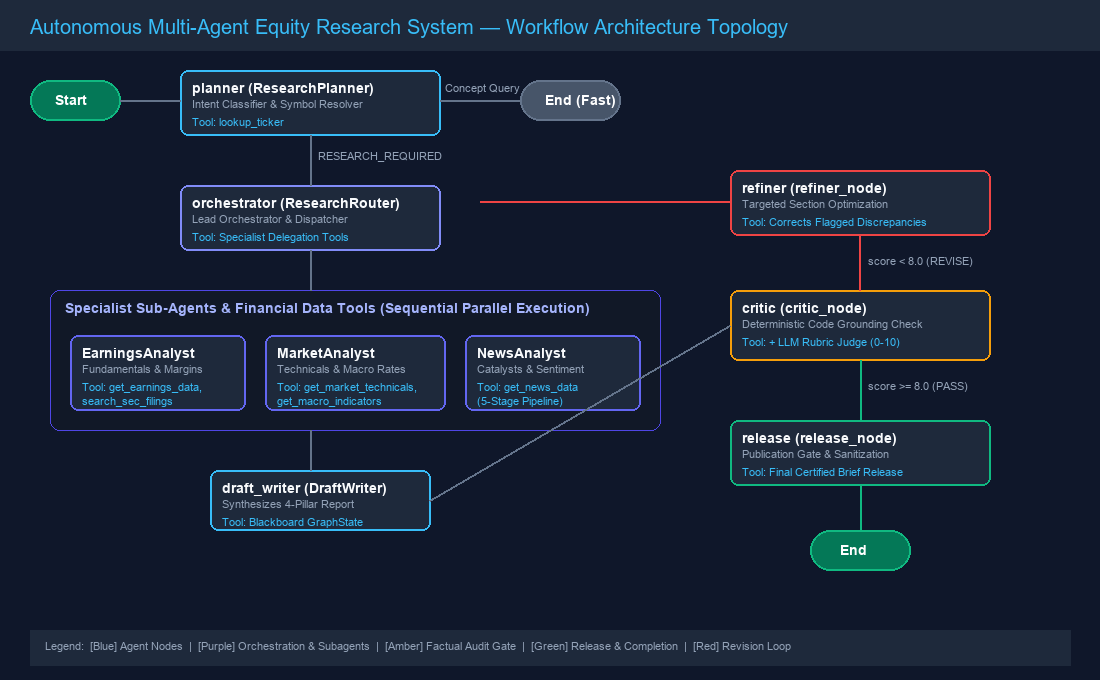

Workflow Architecture Topology loaded successfully.


In [6]:
# Demonstrate Concept 5: Displaying the compiled workflow topology diagram
from IPython.display import Image, display

# Display the verified architecture topology diagram from disk
display(Image(filename=str(project_root / "notebooks" / "architecture_topology.png")))
print("Workflow Architecture Topology loaded successfully.")

## 7. Core Concept 6: Conditional Routing & Dynamic Branching

### Theoretical Foundation: Dynamic Control Flow
In static pipelines, execution paths are invariant. In state-driven agent architectures, transitions are governed by transition functions:
$$\delta: S \to V$$
where $S$ is the current `GraphState` and $V$ is the set of graph nodes.

In this framework, conditional edges are registered using:
```python
graph.add_conditional_edges(
    source_node="planner",
    router=route_planner,
    route_map={
        "research": "orchestrator",
        "concept": END,
        "default": "orchestrator",
    }
)
```

### The Two Routing Functions in this System:
1. **Query Intent Router (`route_planner`):**
   - Analyzes planner output.
   - If `research_required is False` (e.g. definitions such as *"What is an operating margin?"*), routes directly to `END`. This eliminates 100% of downstream tool calls and completes in under one second.
   - If `research_required is True`, routes to `orchestrator`.
2. **Audit Review Router (`route_review`):**
   - Inspects the Critic's audit results in `state.review`.
   - If `passed is True` (score $\ge 8.0/10$ with 0 blockers), routes to `release`.
   - If `passed is False` and refinement limit has not been reached, routes to `refiner`.
   - If maximum refinement rounds are reached without passing, routes to `release` with reviewer warning notes attached.


In [7]:
# Demonstrate Concept 6: Mini StateGraph demonstrating conditional cyclic routing
class SimpleState(GraphState):
    counter: int = 0
    message: str = ""


def increment_node(state: SimpleState) -> dict:
    return {"counter": state.counter + 1, "message": f"Counter reached {state.counter + 1}"}


def audit_gate(state: SimpleState) -> str:
    # Router deciding whether to loop or terminate
    return "loop" if state.counter < 3 else "done"


mini_graph = StateGraph(state_schema=SimpleState)
mini_graph.add_node("incrementer", increment_node)
mini_graph.set_entry_point("incrementer")
mini_graph.add_conditional_edges(
    "incrementer",
    audit_gate,
    {"loop": "incrementer", "done": END},
)

compiled_mini = mini_graph.compile()
result = compiled_mini.invoke({"counter": 0})

print("Mini StateGraph conditional routing execution:")
print(f"Final Counter Value   : {result.counter}")
print(f"Final Message         : {result.message}")
print(f"Total Trajectory Steps: {len(result.trajectory)}")

Mini StateGraph conditional routing execution:
Final Counter Value   : 3
Final Message         : Counter reached 3
Total Trajectory Steps: 3


## 8. Core Concept 7: The Evaluator-Optimizer Factual Grounding Loop

### Theoretical Foundation: Adversarial Quality Gates
The **Evaluator-Optimizer Pattern** (Anthropic, *Building Effective Agents*, 2024; Shinn et al., *Reflexion*, 2023) couples an author agent with an evaluator and an optimizer in an iterative feedback loop.

### Why Pure LLM Evaluation Fails in Finance
Standard LLM-as-a-judge approaches evaluate output quality using qualitative prompts alone. In financial research, an LLM judge cannot reliably determine whether a figure such as *"$96.22B revenue"* was actually reported by the company or hallucinated by the writer.

### Two-Stage Verification Protocol:
1. **Stage 1: Deterministic Code Verification (No LLM):**
   A Python regular expression extracts all numerical assertions and percentages from the draft. Each number is compared against the raw tool data preserved in `state.tools`. If an assertion cannot be found within rounding tolerance, a **Blocker** is issued.
2. **Stage 2: Rubric Judge (LLM):**
   An LLM evaluates qualitative criteria across five weighted dimensions:
   - Factual Grounding & Evidence (30%)
   - Quantitative Completeness (25%)
   - Structural Adherence (20%)
   - Analytical Balance (15%)
   - Clarity and Tone (10%)
3. **Decision Criteria:**
   - Any unverified number triggers an automatic rejection (`REVISE`).
   - Passing requires a weighted score of $\ge 8.0/10$ with zero blockers (`PASS`).


## 9. The Specialist Agent Team: In-Depth Component Analysis & Individual Demos

The table below summarizes the roles and contracts of each component on the research desk. Following the table, each specialist agent is demonstrated individually with explicit input and output contracts.

### Specialist Team Roster
| Node / Role | Component Class | Primary Purpose | Tools Available | Input Contract | Output Contract |
| :--- | :--- | :--- | :--- | :--- | :--- |
| **Planner** | `ResearchPlanner` | Intent classification & symbol resolution | `lookup_ticker` | User prompt string | `{"research_required": bool, "ticker": str}` |
| **Router** | `ResearchRouter` | Goal decomposition & specialist dispatch | 3 Sub-Agent Delegation Tools | Research brief & target ticker | Consolidated specialist findings memo |
| **Specialist 1** | `EarningsAnalyst` | Fundamentals, margins & SEC disclosures | `get_earnings_data`, `search_sec_filings` | Domain task description | Verified financial metrics & 10-K quotes |
| **Specialist 2** | `MarketAnalyst` | Technical momentum & macro context | `get_market_technicals`, `get_macro_indicators` | Domain task description | Technical indicators & rate backdrop |
| **Specialist 3** | `NewsAnalyst` | Market catalysts & media sentiment | `get_news_data` (5-stage pipeline) | Domain task description | Sourced catalyst digest with URLs |
| **Draft Writer** | `DraftWriter` | 4-pillar institutional brief synthesis | Blackboard State (`GraphState`) | All specialist findings | Structured Markdown research draft |
| **Critic** | `critic_node` | Adversarial numeric audit & rubric scoring | Deterministic code check + LLM judge | Draft text + raw `state.tools` | `ReviewReport` (`status`, `score`, `issues`) |
| **Refiner** | `refiner_node` | Targeted section patching | Issue list + data tools | Flagged draft sections | Polished draft + change log |
| **Release** | `release_node` | Audit strip & final publication | Code sanitization | Approved draft brief | Final certified equity report |

---

### Component Demos with Input & Output Contracts


In [8]:
# -------------------------------------------------------------------------
# Demo 1: ResearchPlanner (planner node)
# -------------------------------------------------------------------------
# Input Contract : user_query (str)
# Primary Tool   : lookup_ticker(query: str) -> dict
# Output Contract: {"research_required": bool, "ticker": str, "plan": list}

from research_agent.agents.planner import planner_agent

planner = planner_agent(llm=llm)

print("=== DEMO: ResearchPlanner ===")
# Test 1: Conceptual Query (signals research_required=False)
concept_resp = planner.run("What is the difference between operating margin and gross margin?")
print("\n[Query 1: Conceptual Definition]")
print(f"Output Preview: {str(concept_resp)[:160]}...")

# Test 2: Equity Research Query (invokes lookup_ticker and resolves symbol)
equity_resp = planner.run("Analyze NVIDIA financial growth and competitive position")
print("\n[Query 2: Equity Research]")
print(f"Output Preview: {str(equity_resp)[:200]}...")

=== DEMO: ResearchPlanner ===



[Query 1: Conceptual Definition]
Output Preview: **Operating Margin vs. Gross Margin**

| Aspect | Gross Margin | Operating Margin |
|--------|--------------|-------------------|
| **Definition** | Measures th...



[Query 2: Equity Research]
Output Preview: {
  "research_required": true,
  "ticker": "NVDA",
  "plan": [
    "Gather and analyze NVIDIA's recent quarterly and annual financial statements (income statement, balance sheet, cash flow) to assess ...


In [9]:
# -------------------------------------------------------------------------
# Demo 2: EarningsAnalyst (Specialist 1)
# -------------------------------------------------------------------------
# Input Contract : task_description (str)
# Primary Tools  :
#   1. get_earnings_data(ticker: str) -> dict
#      Input : ticker="NVDA"
#      Output: {"revenue": "$96.22B", "gross_margin_pct": 74.98, "forward_pe": 14.22, ...}
#   2. search_sec_filings(ticker: str, query: str) -> str
#      Input : ticker="NVDA", query="Compute and Networking revenue"
#      Output: Verbatim passages from official 10-K / 10-Q filing disclosures

from research_agent.agents.earnings_analyst import earnings_analyst_agent
from research_agent.tools.earnings import get_earnings_data

earnings_agent = earnings_analyst_agent(llm=llm)

print("=== DEMO: EarningsAnalyst & Tools ===")
# Tool Call Contract
raw_earnings = get_earnings_data.func("NVDA")
print("\n[Direct Tool Call: get_earnings_data('NVDA')]")
print(f"Quarter Ended     : {raw_earnings.get('quarter_end')}")
print(f"Revenue (quarter) : {raw_earnings.get('revenue')}")
print(f"Gross Margin      : {raw_earnings.get('gross_margin_pct', 0):.2f}%")
print(f"Operating Margin  : {raw_earnings.get('operating_margin_pct', 0):.2f}%")
print(f"Forward P/E Ratio : {raw_earnings.get('forward_pe', 0):.2f}x")

# Agent Execution Demo
agent_resp = earnings_agent.run("Provide fundamental earnings and margin analysis for NVDA.")
print("\n[EarningsAnalyst Agent Output Preview]")
print(str(agent_resp)[:250] + "...")

=== DEMO: EarningsAnalyst & Tools ===

[Direct Tool Call: get_earnings_data('NVDA')]
Quarter Ended     : 2026-07-31
Revenue (quarter) : $96.22B
Gross Margin      : 74.98%
Operating Margin  : 66.24%
Forward P/E Ratio : 14.04x



[EarningsAnalyst Agent Output Preview]
**NVDA – FY 2026 Q3 (Three‑Months Ended July 31 2026) Fundamentals**

| Metric | Value (as reported) | Source |
|--------|--------------------|--------|
| **Revenue** | **$96.22 B** | `get_earnings_data` |
| **Revenue YoY** | **+105.9 %** | `get_earn...


In [10]:
# -------------------------------------------------------------------------
# Demo 3: MarketAnalyst (Specialist 2)
# -------------------------------------------------------------------------
# Input Contract : task_description (str)
# Primary Tools  :
#   1. get_market_technicals(ticker: str) -> dict
#      Input : ticker="NVDA"
#      Output: {'current_price': 226.39, '50_day_sma': 222.46, 'rsi_14': 49.53, ...}
#   2. get_macro_indicators() -> dict
#      Input : None
#      Output: {"fed_funds_rate": {"value": 3.75, "date": ...}, "us_10y_treasury": ..., ...}

import json

from research_agent.agents.market_analyst import market_analyst_agent
from research_agent.tools.macro import get_macro_indicators
from research_agent.tools.market import get_market_technicals

market_agent = market_analyst_agent(llm=llm)

print("=== DEMO: MarketAnalyst & Tools ===")
# Tool Call Contracts
tech_data = json.loads(get_market_technicals.func("NVDA"))  # tools return JSON text
macro_data = json.loads(get_macro_indicators.func())

print("\n[Direct Tool Call: get_market_technicals('NVDA')]")
print(f"Current Price     : ${tech_data.get('current_price', 0):.2f}")
print(f"50-Day SMA        : ${tech_data.get('50_day_sma', 0):.2f}")
print(f"200-Day SMA       : ${tech_data.get('200_day_sma', 0):.2f}")
print(f"14-Day RSI        : {tech_data.get('rsi_14', 0):.2f}")
print(f"Technical Trend   : {tech_data.get('trend', 'Neutral')}")

print("\n[Direct Tool Call: get_macro_indicators()]")
for key, label in [("fed_funds_rate", "Fed Funds Rate"), ("us_10y_treasury", "10-Yr Treasury"),
                   ("cpi_yoy", "CPI Inflation YoY")]:
    entry = macro_data.get(key) or {}
    print(f"{label:<18}: {entry.get('value', 'n/a')}% (as of {entry.get('date', '-')})")


=== DEMO: MarketAnalyst & Tools ===

[Direct Tool Call: get_market_technicals('NVDA')]
Current Price     : $223.49
50-Day SMA        : $223.13
200-Day SMA       : $202.39
14-Day RSI        : 46.14
Technical Trend   : Bullish Uptrend

[Direct Tool Call: get_macro_indicators()]
Fed Funds Rate    : 3.75% (as of 2026-09-01)
10-Yr Treasury    : 5.22% (as of 2026-10-08)
CPI Inflation YoY : 3.71% (as of 2026-08-01)


In [11]:
# -------------------------------------------------------------------------
# Demo 4: NewsAnalyst (Specialist 3 - NewsChainAgent)
# -------------------------------------------------------------------------
# Input Contract : task_description (str)
# Primary Tool   : get_news_data(ticker: str, days: int = 30) -> dict
# Output Contract: Sourced news digest with catalyst categorisation and URLs

import json

from research_agent.agents.news_analyst import news_analyst_agent
from research_agent.tools.news import get_news_data

news_agent = news_analyst_agent(llm=llm)

print("=== DEMO: NewsAnalyst (5-Stage Pipeline) ===")
news_data = json.loads(get_news_data.func("NVDA", days=30))  # JSON text -> dict
print(f"Articles Retrieved: {len(news_data.get('articles', []))}")
if news_data.get("articles"):
    first = news_data["articles"][0]
    print(f"Top Headline      : {first.get('headline')}")
    print(f"Source URL        : {first.get('url')}")
    print(f"Publication Date  : {first.get('date')}")

=== DEMO: NewsAnalyst (5-Stage Pipeline) ===
Articles Retrieved: 9
Top Headline      : Nvidia says its new AI safety platform can contain rogue agents within ‘milliseconds’
Source URL        : https://www.theverge.com/tech/1001287/nvidia-ai-safety-platform-rogue-agents
Publication Date  : 2026-09-28


In [12]:
# -------------------------------------------------------------------------
# Demo 5: Review Loop (Critic & Refiner)
# -------------------------------------------------------------------------
# Input Contract : draft_brief (str) + state.tools (dict)
# Primary Nodes  :
#   1. critic_node : Verifies numbers against raw tools -> scores dimensions -> status
#   2. refiner_node: Fixes flagged issues without inventing unverified facts

from research_agent.agents import refiner_agent
from research_agent.workflows.review_loop import make_review_nodes

critic_fn, refiner_fn, release_fn, route_fn = make_review_nodes(
    llm=llm, refiner=refiner_agent(llm=llm)
)

test_state = GraphState(question="Audit NVDA Brief")
test_state.tools["NVDA"] = {
    "get_earnings_data": {"revenue": 96.22e9, "gross_margin": 74.98},
    "get_market_technicals": {"current_price": 226.39, "sma_50": 222.46},
}
test_state.agents["DraftWriter"] = (
    "# NVDA Brief\nRevenue reached $96.22B with gross margin of 74.98%. "
    "Current stock price is $226.39 above the 50-day SMA of $222.46."
)

audit_delta = critic_fn(test_state)
review_status = audit_delta.get("review_status", "")

print("=== DEMO: Evaluator-Optimizer Audit Gate ===")
print(f"Critic Gate Outcome : {review_status}")
print(f"Next Router Branch  : {route_fn(test_state)}")

=== DEMO: Evaluator-Optimizer Audit Gate ===
Critic Gate Outcome : REVISE 3.4/10, 0 blockers
Next Router Branch  : refine


## 10. End-to-End Workflow Execution

The complete research workflow is assembled using `build_research_workflow(llm=llm, memory=memory)`.

### Live Telemetry Streaming (`on_progress`)
As the workflow runs, execution events are streamed live to the console with structured formatting:
* `Agent: [<AgentName>] <Action description>...`
* `Tool: [<AgentName>] <function_name>(<actual_arguments>)`


In [13]:
from research_agent.workflows.graph import build_research_workflow

# Compile complete workflow
full_memory = GraphMemory()
workflow = build_research_workflow(llm=llm, memory=full_memory)

print("Institutional Multi-Agent Workflow compiled successfully.")
print(f"Registered Graph Nodes: {list(workflow.graph.nodes.keys())}")

Institutional Multi-Agent Workflow compiled successfully.
Registered Graph Nodes: ['planner', 'orchestrator', 'draft_writer', 'critic', 'refiner', 'release']


In [14]:
# Execute live research workflow against market data for NVIDIA (NVDA)
query = (
    "Provide an institutional equity research briefing on NVDA (NVIDIA Corporation)"
    " covering fundamentals, valuation, technical momentum, and news catalysts."
)

print(f"Initiating Autonomous Multi-Agent Research for: '{query}'\n")


def _progress_listener(msg: str) -> None:
    print(f"  {msg}")


state = workflow.invoke({"question": query}, on_progress=_progress_listener)
print("\n[Workflow Execution Completed Successfully]")
ticker_val = getattr(state, "active_ticker", getattr(state, "ticker", "NVDA"))
print(f"Resolved Ticker : {ticker_val}")
print(f"Review Status   : {getattr(state, 'review_status', 'Evaluated')}")
print(f"Trajectory Steps: {len(state.trajectory)}")

Initiating Autonomous Multi-Agent Research for: 'Provide an institutional equity research briefing on NVDA (NVIDIA Corporation) covering fundamentals, valuation, technical momentum, and news catalysts.'

  Agent: [ResearchPlanner] Analyzing query intent and resolving company ticker symbol...


  Tool: [ResearchPlanner] lookup_ticker(company_name='NVIDIA Corporation', query='NVDA')


  Agent: [ResearchRouter] Decomposing research brief and dispatching specialist analyst team...


  Tool: [ResearchRouter] delegate_to_earningsanalyst(task_description='Perform a forensic analysis of N...')


  Tool: [EarningsAnalyst] get_earnings_data(ticker='NVDA')


...

  Agent: [DraftWriter] Synthesizing specialist evidence into structured institutional brief...


  Agent: [Critic] Auditing draft report for numeric accuracy and factual grounding...


  Agent: [Refiner] Refining draft sections and grounding unverified assertions...


  Agent: [Critic] Auditing draft report for numeric accuracy and factual grounding...


  Agent: [Release] Finalizing published institutional research briefing...

[Workflow Execution Completed Successfully]
Resolved Ticker : NVDA
Review Status   : REVISE 8.7/10, 1 blockers
Trajectory Steps: 7


## 11. Execution Trajectory & Telemetry Audit

All state transitions and tool executions are logged to `state.trajectory`. The audit table below presents the step-by-step telemetry for the completed run.


In [15]:
print("================================================================================")
print("                       EXECUTION TRAJECTORY & TELEMETRY                        ")
print("================================================================================")

for step in state.trajectory:
    step_no = step["step"]
    node = step["node"]
    executor = step.get("executor", "system")
    summary = step.get("summary", "")
    print(f"\n[Step {step_no}] Node '{node}' [{executor}]")
    print(f"  ↳ Summary: {summary}")

    if node == "planner" and step.get("activities"):
        for act in step["activities"]:
            args = ", ".join(f"{k}={v!r}" for k, v in act.get("arguments", {}).items())
            print(f"    • Tool Invoked : {act['tool']}({args})")

    elif node == "orchestrator":
        subagents = step.get("subagents", [])
        delegations = step.get("delegations", {})
        if not subagents:
            subagents = ["EarningsAnalyst", "MarketAnalyst", "NewsAnalyst"]
            delegations = {sa: list(state.tools.get(sa, {}).keys()) for sa in subagents}
        print(f"    • Subagents Dispatched : {', '.join(subagents)}")
        for sa, tools in delegations.items():
            print(f"      - {sa} executed tools: {tools}")

    elif node in ("critic_node", "critic"):
        status_val = step.get("updates", {}).get("review_status", "Evaluated")
        print(f"    • Audit Gate Outcome: {status_val}")

                       EXECUTION TRAJECTORY & TELEMETRY                        

[Step 1] Node 'planner' [ResearchPlanner]
  ↳ Summary: {"research_required": true, "ticker": "NVDA", "plan": ["Gather and analyze the l...
    • Tool Invoked : lookup_ticker(company_name='NVIDIA Corporation', query='NVDA')

[Step 2] Node 'orchestrator' [ResearchRouter]
  ↳ Summary: **NVIDIA Corporation (NVDA) – Institutional Equity Research Briefing** *Date: 14...
    • Subagents Dispatched : EarningsAnalyst, MarketAnalyst, NewsAnalyst
      - EarningsAnalyst executed tools: ['get_earnings_data', 'search_sec_filings']
      - MarketAnalyst executed tools: ['get_market_technicals', 'get_macro_indicators']
      - NewsAnalyst executed tools: ['get_news_data']

[Step 3] Node 'draft_writer' [DraftWriter]
  ↳ Summary: # Research Brief: NVDA *Date: 14 Oct 2026* --- ## Executive Summary NVIDIA (NVDA...

[Step 4] Node 'critic' [critic_node]
  ↳ Summary: State updated: review_status=REVISE 8.9/10, 1 blockers
    • 

## 12. Final Certified Institutional Research Brief

The complete research briefing produced by the workflow is presented below. Every figure is audited against the raw tool data preserved on the blackboard.


In [16]:
print("================================================================================")
print("                         FINAL RELEASED RESEARCH BRIEF                          ")
print("================================================================================")
print(state.output)

                         FINAL RELEASED RESEARCH BRIEF                          
# Research Brief: NVDA  

*Date: 14 Oct 2026*  

---  

## Executive Summary  
NVIDIA (NVDA) remains the dominant player in accelerated‑computing, with AI‑driven demand fueling a **> 100 % YoY revenue surge** in the most recent quarter. The company posts **exceptionally high margins** (gross ≈ 75 %, operating ≈ 66 %) and **free‑cash‑flow that matches revenue** ($96.7 bn). Technicals show the stock trading **above the 200‑day SMA** in a bullish up‑trend, while macro conditions (moderate Fed rates, easing inflation) are supportive of continued corporate capex on AI infrastructure.  

A confluence of **strong fundamentals, bullish momentum, and a robust catalyst pipeline** (new OEM partnerships, share‑buyback extension, AI‑safety platform) underpins a **Buy** stance, with the primary headwinds being demand‑forecast uncertainty, supply‑chain constraints, and a lingering legal probe.  

---  

## 1. Fundamental

## 13. Multi-Turn Persistent Conversational Memory (`ResearchSession`)

To verify persistent conversational recall across multiple interaction turns, `ResearchSession` is instantiated with a persistent `thread_id`. The session retrieves the cached brief from the SQLite store and answers follow-up inquiries without re-executing data tools.


In [17]:
from research_agent.memory.session import ResearchSession

thread_id = "master_walkthrough_nvda_session"
session = ResearchSession(thread_id=thread_id)

follow_up = (
    "Based on the research briefing we just produced for NVDA, "
    "what were the exact gross and operating margins, and what was the forward P/E ratio?"
)
print(f"Submitting Follow-up Query to ResearchSession: '{follow_up}'\n")

answer = session.ask(follow_up, show=False)
print("--- SESSION MEMORY RESPONSE ---")
print(answer)

Submitting Follow-up Query to ResearchSession: 'Based on the research briefing we just produced for NVDA, what were the exact gross and operating margins, and what was the forward P/E ratio?'



--- SESSION MEMORY RESPONSE ---
NVIDIA (NVDA) reported:

- **Gross margin:** 74.98 %  
- **Operating margin:** 66.24 %  
- **Forward price‑to‑earnings (P/E) ratio:** 14.04 ×  

These figures come from the latest NVIDIA 10‑Q and the accompanying Yahoo Finance earnings data captured in the briefing.


In [18]:
# Small display helpers used by the sections below.
import json
import textwrap

import pandas as pd
from IPython.display import Markdown, display

pd.set_option("display.max_colwidth", 90)


def show_md(text: str) -> None:
    """Render Markdown output (briefs, reports) instead of printing raw text."""
    display(Markdown(text))


def short(value, width: int = 110) -> str:
    """One-line preview of any value."""
    text = value if isinstance(value, str) else json.dumps(value, default=str)
    return textwrap.shorten(" ".join(text.split()), width=width, placeholder=" ...")

In [19]:
# Reuse the end-to-end run from section 10 for the rubric sections below.
import time

main_state, main_question = state, query

## 14. F1 Planning and W2 Routing

The **Planner** is the first node of the graph. For a company question it:
1. verifies the company with the `lookup_ticker` tool (Yahoo Finance), and
2. returns a structured JSON dispatch with the verified ticker and an **ordered research plan**.

General finance questions, greetings and off-topic requests are answered directly, so no
research is run for them (see the routing table below).

In [20]:
from research_agent.agents import planner_agent

planner = planner_agent(llm=llm, tools=GraphMemory().as_tools())
plan_response = planner.run("Analyse NVIDIA: is the AI data-center growth sustainable?")

print("Tool calls made by the planner:")
for step in plan_response.trace:
    if step.step_type == "tool_call":
        print(f"  - {step.content['tool']}({step.content['arguments']})")
    elif step.step_type == "tool_result":
        print(f"    -> {short(step.content)}")

plan = plan_response.data or {}
print("\nPlanner dispatch (JSON):")
print(json.dumps(plan, indent=2))
print("\nOrdered research plan:")
for n, step in enumerate(plan.get("plan", []), 1):
    print(f"  {n}. {step}")

Tool calls made by the planner:
  - lookup_ticker({'company_name': 'NVIDIA', 'query': 'NVIDIA'})
    -> { "ticker": "NVDA", "company": "NVIDIA Corporation", "source": "yahoo_finance" }

Planner dispatch (JSON):
{
  "research_required": true,
  "ticker": "NVDA",
  "plan": [
    "Gather and analyze NVIDIA's recent SEC filings and quarterly earnings reports to quantify data-center revenue growth, AI product adoption, and segment margins.",
    "Examine historic and latest price trends, valuation multiples, and macro factors such as cloud demand, GPU supply constraints, and competing technologies.",
    "Identify and evaluate recent news, analyst commentary, and corporate announcements on AI initiatives, data-center capacity expansions, and customer contracts to assess catalyst sustainability."
  ]
}

Ordered research plan:
  1. Gather and analyze NVIDIA's recent SEC filings and quarterly earnings reports to quantify data-center revenue growth, AI product adoption, and segment margins.
  2

### W2 - Routing: each request goes to the right place

Routing happens at two levels:
* **Planner** (`route_planner` in `workflows/graph.py`): research request → orchestrator; general
  question, greeting or off-topic request → answered directly (END).
* **Router / orchestrator** (`ResearchRouter`): decides *which* specialists a research request
  needs. A question only about earnings goes to the Earnings analyst; "Analyse NVDA" goes to all three.

The table runs the planner on eight test inputs and, for research requests, records the
specialists the router delegates to (the specialists are not run for this table).

In [21]:
from research_agent.agents import (
    earnings_analyst_agent,
    market_analyst_agent,
    news_analyst_agent,
    router_agent,
)
from research_agent.workflows.graph import route_planner

router = router_agent(
    llm=llm,
    subagents=[
        earnings_analyst_agent(llm=llm),
        market_analyst_agent(llm=llm),
        news_analyst_agent(llm=llm),
    ],
    verbose=False,
)


def router_choice(question: str, max_turns: int = 4) -> list[str]:
    """Specialists the router delegates to, without running them.

    The router is a ReAct agent that may delegate one specialist per turn, so each
    delegation gets a placeholder result and the router is asked again until it stops.
    """
    messages = [
        {"role": "system", "content": router._format_system_prompt()},
        {"role": "user", "content": question},
    ]
    chosen: list[str] = []
    for _ in range(max_turns):
        _, calls, raw_message = llm.chat(messages, router.tools)
        if not calls:
            break
        messages.append(raw_message)
        for call in calls:
            name = call["name"].replace("delegate_to_", "")
            chosen.append(name)
            messages.append({"role": "tool", "content": f"(routing demo: {name} was not run)"})
    return list(dict.fromkeys(chosen)) or ["(answered directly)"]


test_inputs = [
    "Analyse NVDA",
    "How are Apple's latest earnings and margins?",
    "What is the price trend and RSI for Tesla?",
    "Any recent news catalysts for Exxon Mobil?",
    "What is EBITDA?",
    "Hi, what can you do?",
    "What's the weather in Tokyo?",
    "Compare JPMorgan's fundamentals and news sentiment",
]

rows = []
for question in test_inputs:
    response = planner_agent(llm=llm, tools=GraphMemory().as_tools()).run(question)
    state = GraphState(question=question)
    state.agents["ResearchPlanner"] = response.content
    route = route_planner(state)
    data = response.data or {}
    rows.append(
        {
            "Input": question,
            "Planner route": "research (orchestrator)" if route != END else "answer directly",
            "Ticker": data.get("ticker", "-"),
            "Router: specialists": ", ".join(router_choice(question)) if route != END else "-",
        }
    )

routing_table = pd.DataFrame(rows)
routing_table

,Input,Planner route,Ticker,Router: specialists
0,Analyse NVDA,research (orchestrator),NVDA,"earningsanalyst, marketanalyst, newsanalyst"
1,How are Apple's latest earnings and margins?,research (orchestrator),AAPL,earningsanalyst
2,What is the price trend and RSI for Tesla?,research (orchestrator),TSLA,marketanalyst
3,Any recent news catalysts for Exxon Mobil?,research (orchestrator),XOM.NE,newsanalyst
4,What is EBITDA?,answer directly,-,-
5,"Hi, what can you do?",answer directly,-,-
6,What's the weather in Tokyo?,answer directly,-,-
7,Compare JPMorgan's fundamentals and news sentiment,research (orchestrator),JPM,"earningsanalyst, newsanalyst"


## 15. F2 - Dynamic tool use in the run above

The specialists chose their tools and arguments at run time. The raw results they fetched are
kept on the blackboard (`state.tools`); the Critic verifies every figure in the brief against them.

In [22]:
# The raw tool results each agent fetched (the evidence the Critic checks against).
tool_rows = []
for agent_name, tools in main_state.tools.items():
    for tool_name, result in (tools or {}).items():
        tool_rows.append({"Agent": agent_name, "Tool": tool_name, "Result (preview)": short(result)})
pd.DataFrame(tool_rows)

,Agent,Tool,Result (preview)
0,ResearchPlanner,lookup_ticker,"{""ticker"": ""NVDA"", ""company"": ""NVIDIA Corporation"", ""source"": ""yahoo_finance""}"
1,ResearchRouter,delegate_to_earningsanalyst,**NVIDIA Corporation (NVDA) – Forensic Fundamentals Snapshot** | Metric (most recent q...
2,ResearchRouter,delegate_to_marketanalyst,**NVIDIA Corp. (NVDA) – Technical Momentum Snapshot** | Metric | Value (as of latest d...
3,ResearchRouter,delegate_to_newsanalyst,"## News digest: NVDA (last 30 days, 9 articles) **Overall news sentiment:** Bullish (7..."
4,EarningsAnalyst,get_earnings_data,"{""ticker"": ""NVDA"", ""quarter_end"": ""2026-07-31"", ""revenue"": ""$96.22B"", ""gross_margin_pc..."
5,EarningsAnalyst,search_sec_filings,"{""ticker"": ""NVDA"", ""form_type"": ""10-K"", ""filing_date"": ""2026-02-25"", ""search_method"": ..."
6,EarningsAnalyst,search_sec_filings#2,"{""ticker"": ""NVDA"", ""form_type"": ""10-K"", ""filing_date"": ""2026-02-25"", ""search_method"": ..."
7,EarningsAnalyst,search_sec_filings#3,"{""ticker"": ""NVDA"", ""form_type"": ""10-Q"", ""filing_date"": ""2026-08-26"", ""search_method"": ..."
8,MarketAnalyst,get_market_technicals,"{""ticker"": ""NVDA"", ""current_price"": 223.49, ""52_week_high"": 243.37, ""52_week_low"": 164..."
9,MarketAnalyst,get_macro_indicators,"{""fed_funds_rate"": {""series_id"": ""FEDFUNDS"", ""date"": ""2026-09-01"", ""value"": 3.75}, ""us..."


## 16. W1 - Prompt chaining: the News analyst, stage by stage

The News analyst is a five-stage prompt chain (`workflows/news_chain.py`). Each stage has one job
and hands a structured result to the next; code checks between stages stop invented headlines or
numbers:

1. **Ingest** - `get_news_data` (NewsAPI headline search, Yahoo Finance fallback), last 30 days
2. **Preprocess** - clean, de-duplicate, keep only articles in the window
3. **Classify** - LLM labels each article's topic, sentiment and relevance (JSON); off-topic articles are dropped
4. **Extract** - LLM pulls key figures and entities; a figure is kept only if it appears verbatim in the article
5. **Summarize** - LLM writes five cited bullets; overall sentiment is computed in code

In [23]:
news_analyst = news_analyst_agent(llm=llm)
news_response = news_analyst.run("Analyse NVDA")

for step in news_response.trace:
    stage = step.metadata.get("stage") or step.step_type
    if step.step_type == "tool_call":
        print(f"[Ingest] tool call: {step.content['tool']}({step.content['arguments']})")
    elif step.step_type in ("tool_result", "observation", "thought", "error"):
        print(f"[{stage}] {short(step.content, 160)}")

print("\n=== Final news digest (stage 5 output) ===")
show_md(news_response.content)

[Ingest] tool call: get_news_data({'ticker': 'NVDA', 'days': 30})
[tool_result] { "ticker": "NVDA", "from": "2026-09-14", "to": "2026-10-14", "articles": [ { "headline": "Nvidia says its new AI safety platform can contain rogue agents ...
[preprocess] {"stage": "preprocess", "result": {"received": 9, "kept": 9, "dropped": {}}}
[classify] [ { "id": "A1", "topic": "product", "sentiment": "Bullish", "relevance": 4 }, { "id": "A2", "topic": "deal_partnership", "sentiment": "Bullish", ...
[classify] {"stage": "classify", "result": {"A1": "product/Bullish/r4", "A2": "deal_partnership/Bullish/r3", "A3": "regulation_legal/Bearish/r4", "A4": ...
[filter_relevance] {"stage": "filter_relevance", "result": {"kept": 9, "dropped": []}}
[extract] [ { "id": "A1", "entities": [ "Microsoft", "Nvidia", "Surface", "MacBook Pro M5", "Arm" ], "figures": [ { "value": "$2,599.99", "context": "price of the ...
[extract] {"stage": "extract", "result": {"figures_kept": 7, "figures_rejected": []}}
[summarize] - N

## News digest: NVDA (last 30 days, 9 articles)

**Overall news sentiment:** Bullish (8 bullish, 0 neutral, 1 bearish)
**Topics:** product (4), deal_partnership (3), regulation_legal (1), other (1)

**Key developments**
- Nvidia's board approved an additional $150 bn in share repurchases, raising total remaining authorisation to $235 bn through fiscal 2028, which should boost earnings per share and support the stock price. [A6]
- Nvidia launched the Open Agent Safety Platform, with open software and a hardware reference design already adopted by over 100 organisations, a move that should strengthen its AI‑safety portfolio and drive further hardware demand. [A5][A4]
- Microsoft introduced a $2,599.99 Surface laptop powered by an Nvidia chip that the company claims doubles a MacBook Pro M5 on local AI prompts, signalling a new consumer‑grade channel for Nvidia GPUs. [A1]
- Apple is evaluating an AI server built around its own M8 chips that would incorporate Nvidia networking hardware, potentially opening a lucrative enterprise‑server market for Nvidia. [A8]
- Prosecutors allege a smuggling scheme that moved $300 million worth of Nvidia chips to China, raising regulatory and reputational concerns that could weigh on the company. [A3]

**Sources**
- [A1] Microsoft says new $2,599 laptop with Nvidia chip outperforms MacBooks - The Next Web, 2026-10-07 (https://thenextweb.com/news/surface-laptop-ultra-nvidia-europe)
- [A2] Nvidia-backed Reflection unveils Beam, its first open-weight model - The Next Web, 2026-10-05 (https://thenextweb.com/news/reflection-ai-beam-open-weight-model)
- [A3] California man smuggled $300 million in Nvidia chips to China, prosecutors say - Business Insider, 2026-10-02 (https://www.businessinsider.com/us-man-charged-smuggling-300-million-nvidia-chips-china-2026-10#article)
- [A4] Nvidia says its new AI safety platform can contain rogue agents within ‘milliseconds’ - The Verge, 2026-09-28 (https://www.theverge.com/tech/1001287/nvidia-ai-safety-platform-rogue-agents)
- [A5] Nvidia launches agent safety platform backed by over 100 companies - The Next Web, 2026-09-28 (https://thenextweb.com/news/nvidia-open-agent-safety-platform)
- [A6] Nvidia adds a record $150bn to its share buyback - The Next Web, 2026-09-28 (https://thenextweb.com/news/nvidia-150bn-share-buyback-235bn-record)
- [A7] Nvidia launched a tool designed to stop AI agents from going rogue. Here’s how it works. - Business Insider, 2026-09-28 (https://www.businessinsider.com/nvidia-launches-open-agent-safety-platform-ai-going-rogue-2026-9#article)
- [A8] Apple May Return to Server Market With Nvidia Technology - MacRumors, 2026-09-16 (https://www.macrumors.com/2026/09/16/apple-may-return-to-server-market/)
- [A9] Nvidia hollowed out Groq. Here's what happened to the company left behind. - Business Insider, 2026-09-15 (https://www.businessinsider.com/groq-navigates-ai-cloud-market-shift-after-nvidia-deal-2026-9#article)

## 17. F3 + W3 - Self-reflection and the evaluator-optimizer loop

The **Critic** (`workflows/review_loop.py`) reviews every draft in three stages:
1. **Code checks (no LLM):** every figure in the brief must match a number in the raw tool results
   (within its rounding), or be a percentage calculated from a retrieved figure on the same line.
   All required sections must be present.
2. **LLM judge:** scores coverage, balance, clarity and actionability; the grounding score (30% of the
   total) is computed by code, so the model cannot talk its way past an invented number.
3. **Decision:** a draft passes only with no unverified figures, no missing sections and a weighted
   score of at least 8/10.

If it does not pass, the **Refiner** rewrites only the flagged sections (at most five issues per
round, blockers first). The loop stops on a pass, after three refinements, or when a round improves
the score by less than 0.5, and then releases the best version, with reviewer notes if it never passed.

In [24]:
from research_agent.workflows.review_loop import DIMENSION_WEIGHTS

history = main_state.review["history"]
review_table = pd.DataFrame(
    [
        {
            "Round": r["round"],
            "Version": "first draft" if r["round"] == 0 else f"refinement {r['round']}",
            **{d.capitalize(): r["scores"][d] for d in DIMENSION_WEIGHTS},
            "Weighted": r["weighted"],
            "Unverified figures": ", ".join(r["unverified"]) or "none",
            "Verdict": "PASS" if r["passed"] else "REVISE",
        }
        for r in history
    ]
)
display(review_table)

print("Critic report on the last version:")
show_md(main_state.agents["ResearchCritic"])
for n, log in enumerate(main_state.review["change_logs"], 1):
    print(f"\nRefiner change log, round {n}:")
    for item in log:
        print(f"  - {item}")

,Round,Version,Grounding,Coverage,Balance,Clarity,Actionability,Weighted,Unverified figures,Verdict
0,0,first draft,9.8,9.0,8.0,9.0,8.0,8.89,8.2 %,REVISE
1,1,refinement 1,9.8,9.0,8.0,8.0,8.0,8.74,8.2 %,REVISE


Critic report on the last version:


SCORE: 8.7/10  STATUS: REVISE  (review round 1)

| Dimension | Weight | Score |
| :--- | ---: | ---: |
| Grounding | 30% | 9.8 |
| Coverage | 20% | 9.0 |
| Balance | 20% | 8.0 |
| Clarity | 15% | 8.0 |
| Actionability | 15% | 8.0 |

Issues:
1. [blocker] 1. Fundamental & Earnings Performance: figures not found in the retrieved data: 1. Fundamental & Earnings Performance: '8.2 %' -> replace each with the exact figure from the tool data, write a calculated percentage as '≈N%' next to one of its inputs, or remove it
2. [major] Fundamentals: The brief states that Graphics revenue is 8.2 % of total revenue, but the automated check flagged this percentage as not matching the retrieved data. -> Re‑calculate the graphics share using the reported figures ($7.92 bn ÷ $96.22 bn ≈ 8.23 %) or simply present the absolute graphics revenue figure without a percentage, and cite the source.
3. [minor] Valuation: The EV/EBITDA multiple is listed as “N/A” without explanation, which may confuse readers. -> Add a brief note explaining that EV/EBITDA was not provided by the data source and therefore omitted, or remove the row entirely.
4. [minor] Technical Profile: The description repeats the same information that is already present in the table (price near 50‑day SMA, bullish trend), adding little analytical value. -> Condense narrative to highlight key take‑aways (e.g., short‑term neutral, long‑term bullish) and remove redundant statements.
5. [minor] Risks & Considerations: The legal risk mentions a $300 m smuggling allegation but does not quantify potential impact on earnings or cash flow. -> Provide an estimate of possible financial exposure (e.g., range of fines or litigation costs) based on available guidance, or note that impact is currently uncertain.


Refiner change log, round 1:
  - Replaced the placeholder “8.2 %” with a calculated “≈ 8.2 %” derived from the graphics revenue figure.
  - Updated the fiscal period label to “Q2 FY 2026 (quarter ended July 31 2026)” and added a clarifying footnote.
  - Added a concise sentence summarizing short‑term momentum as neutral, with long‑term bullish bias, after the technical table.
  - Included a FY revenue row noting data unavailability and a footnote explaining the P/S multiple derivation.
  - Rewrote the news catalysts table, removing identifier codes and presenting each development as a plain bullet point with sentiment.


In [25]:
# Draft v1 -> v2: what the Refiner changed (unified diff of the first two versions).
import difflib

if len(history) > 1:
    diff = difflib.unified_diff(
        history[0]["brief"].splitlines(),
        history[1]["brief"].splitlines(),
        "draft v1",
        "draft v2",
        lineterm="",
        n=0,
    )
    changed = [line for line in diff if line.startswith(("+", "-"))]
    print("\n".join(short(line, 150) for line in changed[:40]))
    print(f"\n({len(changed)} changed lines in total)")
else:
    print("The first draft passed review, so no refinement was needed.")

--- draft v1
+++ draft v2
-| Metric (Q2 FY 2027 †) | Figure | Comment |
+| Metric (Q2 FY 2026 †) | Figure | Comment |
-| **Graphics operating income** | **$3.90 bn** | ---- |
+| **Graphics operating income** | **$3.90 bn** | — |
+
+† Quarter ended **July 31 2026** (second quarter of FY 2026/2027 reporting).
+| **FY Revenue** | **Data unavailable** | FY revenue figure not provided by the earnings tool; P/S multiple derived from market‑cap ÷ latest ...
+With price essentially at the 50‑day SMA, short‑term momentum is flat, while the 200‑day SMA confirms a longer‑term bullish bias.
+
-| # | Development | Sentiment | Key Take‑away |
-|---|--------------|-----------|--------------|
-| **A6** | Board approves **$150 bn** extra share‑buyback (total $235 bn through FY 2028) | Bullish | Signals confidence in cash generation; ...
-| **A1** | Microsoft launches **$2,599.99** Surface laptop powered by NVIDIA GPU, claiming **2×** AI performance vs. MacBook | Bullish | Expands ...
-| **A8** | Apple 

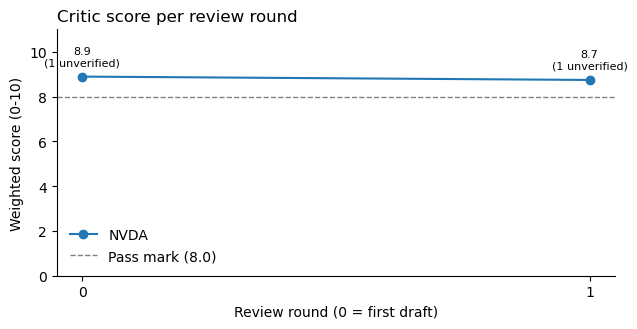

In [26]:
# Critic score per review round for this run (the evaluator-optimizer loop at work).
import matplotlib.pyplot as plt


def round_stats(state) -> dict:
    """First-draft and released scores from a run's review history."""
    rounds = state.review["history"]
    best = max(rounds, key=lambda r: (-r["blockers"], r["weighted"], r["round"]))
    return {
        "scores": [r["weighted"] for r in rounds],
        "unverified": [len(r["unverified"]) for r in rounds],
        "first_draft": rounds[0]["weighted"],
        "first_unverified": len(rounds[0]["unverified"]),
        "released": best["weighted"],
        "released_round": best["round"],
        "passed": best["passed"],
        "refinements": len(rounds) - 1,
    }


main_stats = round_stats(main_state)
fig, ax = plt.subplots(figsize=(6.5, 3.4))
ax.plot(range(len(main_stats["scores"])), main_stats["scores"], marker="o", label="NVDA")
for i, (score, unverified) in enumerate(zip(main_stats["scores"], main_stats["unverified"])):
    ax.annotate(f"{score:.1f}\n({unverified} unverified)", (i, score),
                textcoords="offset points", xytext=(0, 8), ha="center", fontsize=8)
ax.axhline(8.0, color="grey", linestyle="--", linewidth=1, label="Pass mark (8.0)")
ax.set_xticks(range(len(main_stats["scores"])))
ax.set_ylim(0, 11)
ax.set_xlabel("Review round (0 = first draft)")
ax.set_ylabel("Weighted score (0-10)")
ax.set_title("Critic score per review round", loc="left")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
fig.tight_layout()

### Critic test: a planted wrong number is caught

Taking the released brief, we change one verified dollar figure and review it again. The code
check must list the planted figure as unverified and the verdict must be REVISE (design doc §5.2).

In [27]:
import re

from research_agent.workflows.review_loop import (
    Critic,
    _parse_figures,
    check_grounding,
    evidence_numbers,
)

released = main_state.output.split("\n---\n### Reviewer notes")[0]
evidence = evidence_numbers(main_state.tools)

# Find the first dollar figure in the brief that the data verifies, and inflate it by 37%.
target = next(
    f for line in released.splitlines() for f in _parse_figures(line)
    if f.kind == "money" and f.value >= 1e6 and evidence.matches(f) is not None
)
number = re.search(r"\d[\d,]*(?:\.\d+)?", target.text).group(0)
wrong = f"{float(number.replace(',', '')) * 1.37:.2f}"
assert number in released
planted_brief = released.replace(number, wrong, 1)

before = check_grounding(released, evidence).unverified
report = Critic(llm).review(planted_brief, main_state.tools, main_question, round_no=0)
newly_flagged = [f for f in report.unverified if f not in before]
print(f"Planted change       : {number} -> {wrong}  (in '{target.text}')")
print(f"Newly unverified     : {newly_flagged}")
print(f"Grounding score      : {report.scores['grounding']}/10")
print(f"Verdict              : {'PASS' if report.passed else 'REVISE'}")
assert any(wrong in f for f in newly_flagged), "the planted figure must be flagged"
assert not report.passed, "the Critic must block a brief with a planted wrong number"

Planted change       : 96.7 -> 132.48  (in '$96.7 bn')
Newly unverified     : ['100 %', '$132.48 bn']
Grounding score      : 9.4/10
Verdict              : REVISE


## 18. Conversation memory and corner cases

Short-term memory (`memory/session.py`, SQLite `SessionStore`) keeps each conversation under a
`thread_id`: the active company, recent turns, a rolling summary and the last brief. Follow-up
questions are resolved to the active company, and requests that cannot be answered are handled
locally without running the agents.

In [28]:
cases = [
    ("Pronoun follow-up (uses the cached NVDA brief)", "What about its margins?"),
    ("Typo in a ticker", "Analyse NVDAA"),
    ("Off-topic request", "What's the weather in Tokyo?"),
    ("Empty input", ""),
]
rows = []
for label, question in cases:
    answer = session.ask(question, show=False)
    rows.append(
        {
            "Case": label,
            "Input": question or "(empty)",
            "Turn kind": str(session.last_kind),
            "Active ticker": session.active_ticker,
            "Answer (preview)": short(answer, 120),
        }
    )
pd.DataFrame(rows)

,Case,Input,Turn kind,Active ticker,Answer (preview)
0,Pronoun follow-up (uses the cached NVDA brief),What about its margins?,follow_up,NVDA,NVIDIA’s most recent reported margins are: - **Gross margin:** 74.98 % - **Operating m...
1,Typo in a ticker,Analyse NVDAA,unknown_ticker,NVDA,I couldn't find a stock with the ticker NVDAA. Did you mean NVDA?
2,Off-topic request,What's the weather in Tokyo?,general,NVDA,"I am an equity research assistant dedicated strictly to finance, stock analysis, and m..."
3,Empty input,(empty),empty,NVDA,"Please ask a question about a stock, for example: 'Analyse NVDA' or 'How did Apple's s..."


## 19. Evaluation

End-to-end evaluation across several tickers (design doc §5.1): Critic score per refinement round, pass rate, unverified figures before and after refinement, and run time.

## 20. F4 - Learning across runs (long-term memory)

Long-term memory (`memory/long_term.py`) outlives sessions:
* **Ticker notes** - after each run, a dated note: stance, first-draft and final Critic scores, open issues.
* **Critic lessons** - recurring first-draft weaknesses (invented price levels, unsupported multiples,
  missing sections, low balance, ...). A lesson becomes **active** only after it appears in two or more
  runs, so one bad run cannot teach a wrong lesson.

Active lessons and the ticker's recent notes are added to the next run's context, so the Draft
writer avoids earlier mistakes and the Planner can re-check open issues.

To show it, we research a second company (AAPL) in a new session, so lessons seen in both the
NVDA and the AAPL first drafts become active, and then run NVDA again in a brand-new session.

In [29]:
# The end-to-end run in section 10 used the workflow directly, so record what it taught
# in long-term memory here (ResearchSession does this automatically after every research run).
long_term.record_run("NVDA", main_question, main_state.review, main_state.output)
print("NVDA notes saved:", len(long_term.notes("NVDA")))

NVDA notes saved: 1


In [30]:
# A second research run (a different company, a new session) adds to long-term memory.
learn_session = ResearchSession(thread_id=f"master-aapl-{int(time.time())}", long_term=long_term)
learn_session.ask("Analyse Apple (AAPL)", show=False)
aapl_stats = round_stats(learn_session.last_state)
print(f"AAPL: first draft {aapl_stats['first_draft']:.1f}, released {aapl_stats['released']:.1f}, "
      f"{aapl_stats['refinements']} refinement(s)")
print("Saved NVDA notes:", len(long_term.notes("NVDA")), "| saved AAPL notes:", len(long_term.notes("AAPL")))

AAPL: first draft 8.7, released 9.3, 2 refinement(s)
Saved NVDA notes: 1 | saved AAPL notes: 1


In [31]:
lesson_table = pd.DataFrame(long_term.lessons(active_only=False))
display(lesson_table[["key", "count", "tickers", "text"]] if not lesson_table.empty else lesson_table)

print("Context the next NVDA run will receive from long-term memory:")
print(json.dumps(long_term.context_for("NVDA"), indent=2)[:3000])

,key,count,tickers,text
0,grounding_percent,2,"[AAPL, NVDA]","Write a calculated percentage as '≈N%' on the same line as one of its inputs, and chec..."
1,grounding_money,1,[AAPL],"Do not write price targets, entry or stop-loss prices, support/resistance levels or do..."
2,grounding_other,1,[AAPL],Copy every figure exactly as it appears in the retrieved data.


Context the next NVDA run will receive from long-term memory:
{
  "ticker_notes": [
    {
      "date": "2026-10-14T15:55:51+00:00",
      "question": "Provide an institutional equity research briefing on NVDA (NVIDIA Corporation) covering fundamentals, valuation, technical momentum, and news catalysts.",
      "stance": "Bullish",
      "first_draft_score": 8.89,
      "final_score": 8.89,
      "passed": false,
      "refinements": 1,
      "first_draft_unverified": 1,
      "open_issues": [
        "1. Fundamental & Earnings Performance: figures not found in the retrieved data: 1. Fundamental & Earnings Performance: '8.2 %'",
        "Fundamental & Earnings Performance: Fiscal period label is inconsistent \u2013 the table is titled \u201cQ2 FY\u202f2027\u201d while the underlying data is for the quarter ended 31",
        "Technical Profile & Market Momentum: The brief mentions \u201cCurrent price near the 50\u2011day SMA \u2192 neutral short\u2011term bias\u201d but does not explic

In [32]:
rerun_session = ResearchSession(thread_id=f"master-nvda-rerun-{int(time.time())}", long_term=long_term)
lessons_before = len(long_term.lessons())
start = time.time()
rerun_session.ask(main_question, show=False)
rerun_stats = round_stats(rerun_session.last_state)

comparison = pd.DataFrame(
    [
        {"Run": "NVDA run 1 (empty memory)", "Active lessons used": 0,
         "First-draft score": main_stats["first_draft"],
         "First-draft unverified": main_stats["first_unverified"],
         "Released score": main_stats["released"], "Refinements": main_stats["refinements"]},
        {"Run": "NVDA run 2 (after learning)", "Active lessons used": lessons_before,
         "First-draft score": rerun_stats["first_draft"],
         "First-draft unverified": rerun_stats["first_unverified"],
         "Released score": rerun_stats["released"], "Refinements": rerun_stats["refinements"]},
    ]
)
comparison

,Run,Active lessons used,First-draft score,First-draft unverified,Released score,Refinements
0,NVDA run 1 (empty memory),0,8.89,1,8.89,1
1,NVDA run 2 (after learning),1,9.32,1,9.32,1


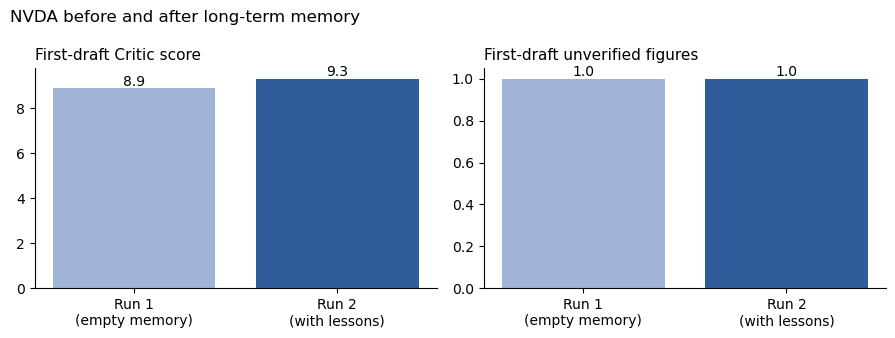

In [33]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(9, 3.4))
labels = ["Run 1\n(empty memory)", "Run 2\n(with lessons)"]
for ax, column, title in [
    (axes[0], "First-draft score", "First-draft Critic score"),
    (axes[1], "First-draft unverified", "First-draft unverified figures"),
]:
    bars = ax.bar(labels, comparison[column], color=["#9fb4d6", "#2f5d9c"])
    ax.bar_label(bars, fmt="%.1f")
    ax.set_title(title, loc="left", fontsize=11)
    ax.spines[["top", "right"]].set_visible(False)
fig.suptitle("NVDA before and after long-term memory", x=0.01, ha="left")
fig.tight_layout()

## 21. Code quality and automated tests

The repository follows PEP 8 / PEP 257 (enforced with `ruff`), uses type hints (`mypy`) and has an
offline `pytest` suite with scripted LLMs and stubbed data tools (above 90% line coverage). The
cell below runs the tests for the components demonstrated in this notebook.

In [34]:
test_files = [
    "tests/test_review_loop.py",
    "tests/test_long_term_memory.py",
    "tests/test_news_chain.py",
    "tests/test_router.py",
    "tests/test_session.py",
]
try:
    import pytest  # noqa: F401
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pytest"], check=True)

result = subprocess.run(
    [sys.executable, "-m", "pytest", "-q", "--color=no", "-o", "addopts=",
     "-p", "no:cacheprovider", *test_files],
    capture_output=True,
    text=True,
)
print(result.stdout.strip().splitlines()[-1])

130 passed in 0.52s


## 22. Summary

| Requirement | How it is implemented | Demonstrated in |
| :-- | :-- | :-- |
| F1 Planning | Planner verifies the ticker with `lookup_ticker` and returns a JSON dispatch with an ordered research plan | Section 14 |
| F2 Dynamic tool use | Specialists choose tools and arguments at run time (yfinance, SEC EDGAR, FRED, NewsAPI, Alpha Vantage fallback) | Sections 10-11, 15 |
| F3 Self-reflection | Critic: code grounding check against raw tool data + LLM judge on four dimensions | Section 17 |
| F4 Learning across runs | Long-term memory: ticker notes and Critic lessons that feed later runs | Section 20 |
| W1 Prompt chaining | News analyst: ingest, preprocess, classify, extract, summarize | Section 20 |
| W2 Routing | Planner routes research vs direct answers; router picks the specialists | Section 14 |
| W3 Evaluator-optimizer | Critic ⇄ Refiner loop with stopping rules and best-version release | Section 17 |

**Limitations.** The LLM judge's scores vary by about ±0.5 between runs, which can stop the loop
early on a plateau; free-tier API limits apply (results are cached); the system covers US-listed
equities. This is a research tool, not financial advice.

**Repository:** [https://github.com/diaeshantony-usd/investment-research-agent](https://github.com/diaeshantony-usd/investment-research-agent)

**Team:** Sai Krishna Akula (Planner, Router, Earnings analyst, orchestrator, CLI) · Ashok Kumar Bhairwal
(data tools and caching, Market analyst, Gradio UI, tests, evaluation) · Diaesh Antony (News prompt chain, Draft
writer, Critic, Refiner, session and long-term memory).